# CLAM-TR v16: Validation Experiments

## Purpose
This notebook validates the architecture contribution and identifies the TRUE source of improvement.

## Critical Issues to Address
1. **BUG**: gamma/coords NOT used in RetentionHead (spatial decay never applied because `use_spatial=False`)
2. **UNKNOWN**: Is the improvement from RetNet or just ConcatFusion?
3. **UNKNOWN**: Are your extracted features correct vs UNI's official features?

## Experiments

| Exp ID | Description | Purpose |
|--------|-------------|---------|
| V1_ABMIL | Simple ABMIL baseline | Is complex architecture needed? |
| V2_ABMIL_GATED | Gated ABMIL (CLAM-style) | Standard CLAM baseline |
| V3_BROKEN | Current F3_ConcatFusion (use_spatial=False) | Reference (bug included) |
| V4_FIXED | F3_ConcatFusion with FIXED RetNet (use_spatial=True) | Does spatial retention help? |
| V5_CONCAT_ONLY | CLAM + ConcatFusion (NO RetNet) | Is RetNet needed at all? |
| V6_UNI_FEATURES | Fixed model on UNI's pre-extracted features | Validate extraction |

**Total: 6 experiments × 5-fold CV = 30 runs**

---

## Best Current Result (for reference)
- **Model**: UNI + CLAM + RetNet + ConcatFusion (F3_ConcatFusion)
- **QWK**: 0.8832 ± 0.029 (Level 0, 20x magnification)
- **Dataset**: 600 slides (100 per ISUP grade)

## 1. IMPORTS AND SETUP

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_score,
    recall_score
)
from scipy import stats
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Google Drive mount
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except:
    IN_COLAB = False
    print('Not in Colab environment')

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'CUDA device: {torch.cuda.get_device_name(0)}')

Mounted at /content/drive
PyTorch version: 2.9.0+cu126
CUDA available: True
CUDA device: Tesla T4


## 2. CONFIGURATION

In [2]:
CONFIG = {
    # Paths
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/uni/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v16_validation/',
    'uni_features_dir': '/content/drive/MyDrive/UNI_PANDA_Features/',  # For V6

    # Model
    'feature_dim': 1024,  # UNI encoder (1536 for UNI2-h)
    'hidden_dim': 512,
    'n_classes': 6,
    'num_heads': 4,

    # Best HP from ablation
    'dropout': 0.15,
    'attention_temp': 0.7,
    'lr': 1e-4,
    'weight_decay': 1e-5,

    # RetNet specific
    'gamma_values': [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995],

    # Training
    'epochs': 50,
    'early_stopping_patience': 10,

    # CV
    'n_folds': 5,
    'seed': 42,
}

# Set seeds
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.cuda.manual_seed_all(CONFIG['seed'])

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

os.makedirs(CONFIG['results_dir'], exist_ok=True)
print(f'Results will be saved to: {CONFIG["results_dir"]}')

Device: cuda
Results will be saved to: /content/drive/MyDrive/CLAM_TR_Results/v16_validation/


## 3. CHECKPOINT MANAGER

In [3]:
class CheckpointManager:
    """Manages checkpoints for resumable training."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_file = os.path.join(checkpoint_dir, 'v16_experiment_progress.json')
        self.fold_progress_file = os.path.join(checkpoint_dir, 'v16_fold_progress.json')

    def _save_json(self, filepath, data):
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f:
                    json.dump(data, f, indent=2, default=str)
                return True
            except Exception as e:
                print(f'Save attempt {attempt+1} failed: {e}')
                time.sleep(1)
        return False

    def _load_json(self, filepath):
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    def get_completed_experiments(self):
        return self._load_json(self.progress_file)

    def is_experiment_completed(self, experiment_name):
        return experiment_name in self.get_completed_experiments()

    def save_experiment_result(self, experiment_name, results):
        data = self._load_json(self.progress_file)
        data[experiment_name] = {
            'results': results,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_file, data)
        print(f'  [Checkpoint] Saved {experiment_name}')

    def load_experiment_result(self, experiment_name):
        data = self.get_completed_experiments()
        if experiment_name in data:
            return data[experiment_name]['results']
        return None

    def get_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        return data.get(experiment_name, {'completed_folds': [], 'fold_results': []})

    def save_fold_result(self, experiment_name, fold_idx, fold_metrics):
        data = self._load_json(self.fold_progress_file)

        if experiment_name not in data:
            data[experiment_name] = {
                'completed_folds': [],
                'fold_results': [],
                'started_at': datetime.now().isoformat()
            }

        if fold_idx not in data[experiment_name]['completed_folds']:
            data[experiment_name]['completed_folds'].append(fold_idx)
            data[experiment_name]['fold_results'].append({
                'fold': fold_idx,
                'metrics': fold_metrics,
                'completed_at': datetime.now().isoformat()
            })

        self._save_json(self.fold_progress_file, data)

    def clear_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        if experiment_name in data:
            del data[experiment_name]
            self._save_json(self.fold_progress_file, data)

    def get_status(self):
        experiments = self.get_completed_experiments()
        fold_data = self._load_json(self.fold_progress_file)
        return {
            'completed_experiments': len(experiments),
            'in_progress_experiments': len(fold_data),
            'experiment_names': list(experiments.keys()),
            'in_progress_names': list(fold_data.keys())
        }

# Initialize
checkpoint_manager = CheckpointManager(CONFIG['results_dir'])
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')


[Checkpoint Status]
  Completed experiments: 0
  In-progress experiments: 0


## 4. METRICS COMPUTATION

In [4]:
def compute_all_metrics(y_true, y_pred):
    """Compute ALL metrics for evaluation."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # 1. QWK (Main Metric)
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    # 2. BINARY METRICS (Cancer vs No Cancer)
    y_true_binary = (y_true > 0).astype(int)
    y_pred_binary = (y_pred > 0).astype(int)

    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)
    binary_precision = precision_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_recall = recall_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)

    tn = ((y_true_binary == 0) & (y_pred_binary == 0)).sum()
    fp = ((y_true_binary == 0) & (y_pred_binary == 1)).sum()
    binary_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    # 3. GRADING METRICS (6-class)
    grading_accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # 4. PER-GRADE METRICS
    per_grade_accuracy = {}
    per_grade_f1 = {}
    per_grade_support = {}

    f1_per_class = f1_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)

    for grade in range(6):
        mask = (y_true == grade)
        support = mask.sum()
        per_grade_support[grade] = int(support)

        if support > 0:
            per_grade_accuracy[grade] = float((y_pred[mask] == grade).mean())
        else:
            per_grade_accuracy[grade] = 0.0

        per_grade_f1[grade] = float(f1_per_class[grade])

    # 5. CONFUSION MATRIX
    cm = confusion_matrix(y_true, y_pred, labels=range(6))

    return {
        'qwk': float(qwk),
        'binary_accuracy': float(binary_accuracy),
        'binary_precision': float(binary_precision),
        'binary_recall': float(binary_recall),
        'binary_specificity': float(binary_specificity),
        'binary_f1': float(binary_f1),
        'grading_accuracy': float(grading_accuracy),
        'macro_f1': float(macro_f1),
        'weighted_f1': float(weighted_f1),
        'per_grade_accuracy': per_grade_accuracy,
        'per_grade_f1': per_grade_f1,
        'per_grade_support': per_grade_support,
        'confusion_matrix': cm.tolist(),
    }

## 5. LOSS FUNCTIONS

In [5]:
class FocalLoss(nn.Module):
    """Focal Loss for class imbalance."""
    def __init__(self, gamma=1.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

---

# PART 1: MODEL IMPLEMENTATIONS

## 5.1 V1_ABMIL: Simple ABMIL Baseline

In [6]:
class SimpleABMIL(nn.Module):
    """
    Attention-Based MIL (Ilse et al., 2018)
    The standard baseline for MIL in pathology.

    NO spatial information, NO gating, just basic attention pooling.
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25):
        super().__init__()

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Simple attention mechanism (no gating)
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        # Classifier
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, features, coords=None):
        """
        Args:
            features: [N, feature_dim] patch features
            coords: [N, 2] - IGNORED in simple ABMIL
        """
        # Transform features
        h = self.feature_transform(features)  # [N, 512]

        # Compute attention weights
        a = self.attention(h)  # [N, 1]
        a = torch.softmax(a, dim=0)  # [N, 1]

        # Weighted sum
        M = torch.sum(a * h, dim=0)  # [512]

        # Classify
        logits = self.classifier(M)  # [6]

        return logits, a

# Test
model = SimpleABMIL()
x = torch.randn(100, 1024)
logits, attn = model(x)
print(f'SimpleABMIL output: {logits.shape}, attention: {attn.shape}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

SimpleABMIL output: torch.Size([6]), attention: torch.Size([100, 1])
Parameters: 593,671


## 5.2 V2_ABMIL_GATED: Gated ABMIL (CLAM-style)

In [7]:
class GatedABMIL(nn.Module):
    """
    Gated Attention MIL (CLAM-style attention)

    Uses sigmoid gating on the attention mechanism.
    Still NO spatial information.
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25):
        super().__init__()

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Gated attention (CLAM-style)
        self.attention_V = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Tanh()
        )
        self.attention_U = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Sigmoid()
        )
        self.attention_w = nn.Linear(256, 1)

        # Classifier
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, features, coords=None):
        """
        Args:
            features: [N, feature_dim]
            coords: [N, 2] - IGNORED in Gated ABMIL
        """
        # Transform
        h = self.feature_transform(features)  # [N, 512]

        # Gated attention: V * U (element-wise gating)
        A_V = self.attention_V(h)  # [N, 256]
        A_U = self.attention_U(h)  # [N, 256]
        a = self.attention_w(A_V * A_U)  # [N, 1]
        a = torch.softmax(a, dim=0)

        # Weighted sum
        M = torch.sum(a * h, dim=0)  # [512]

        # Classify
        logits = self.classifier(M)

        return logits, a

# Test
model = GatedABMIL()
x = torch.randn(100, 1024)
logits, attn = model(x)
print(f'GatedABMIL output: {logits.shape}, attention: {attn.shape}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

GatedABMIL output: torch.Size([6]), attention: torch.Size([100, 1])
Parameters: 790,791


## 5.3 FIXED RetentionHead (Uses Coordinates!)

In [8]:
class FixedRetentionHead(nn.Module):
    """
    FIXED RetNet with actual spatial decay using coordinates.

    BUG FIX: The original implementation had use_spatial=False by default,
    which meant coordinates were NEVER passed to the retention heads.

    This version ALWAYS uses spatial coordinates for distance-based decay.
    """
    def __init__(self, hidden_dim=512, num_heads=4,
                 gamma_values=[0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995],
                 dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads

        # Learnable gamma for each head (controls decay rate)
        # Higher gamma = slower decay = longer range attention
        initial_gamma = gamma_values[:num_heads] if len(gamma_values) >= num_heads else \
                        gamma_values + [0.95] * (num_heads - len(gamma_values))
        self.gamma = nn.Parameter(torch.tensor(initial_gamma).float())

        # QKV projections
        self.W_Q = nn.Linear(hidden_dim, hidden_dim)
        self.W_K = nn.Linear(hidden_dim, hidden_dim)
        self.W_V = nn.Linear(hidden_dim, hidden_dim)

        # Output projection
        self.W_O = nn.Linear(hidden_dim, hidden_dim)

        # Normalization and dropout
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

        # Learnable coordinate scale
        self.coord_scale = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, coords):
        """
        Args:
            x: [K, hidden_dim] - patch features
            coords: [K, 2] - patch coordinates (x, y) - REQUIRED!

        Returns:
            out: [hidden_dim] - slide representation
            attn: [K, K] - attention weights for visualization
        """
        K = x.size(0)

        # === SPATIAL DISTANCE COMPUTATION ===
        coords_float = coords.float()

        # Normalize coordinates to [0, 1] range
        coords_min = coords_float.min(dim=0, keepdim=True)[0]
        coords_norm = coords_float - coords_min
        coords_max = coords_norm.max(dim=0, keepdim=True)[0]
        coords_max = torch.clamp(coords_max, min=1.0)  # Avoid division by zero
        coords_norm = coords_norm / coords_max

        # Pairwise Euclidean distance
        dist = torch.cdist(coords_norm, coords_norm)  # [K, K]

        # Scale distances (learnable)
        dist = dist * torch.abs(self.coord_scale)

        # === MULTI-HEAD QKV ===
        Q = self.W_Q(x)  # [K, hidden_dim]
        K_proj = self.W_K(x)  # [K, hidden_dim]
        V = self.W_V(x)  # [K, hidden_dim]

        # Reshape for multi-head attention: [K, hidden_dim] -> [num_heads, K, head_dim]
        Q = Q.view(K, self.num_heads, self.head_dim).transpose(0, 1)
        K_proj = K_proj.view(K, self.num_heads, self.head_dim).transpose(0, 1)
        V = V.view(K, self.num_heads, self.head_dim).transpose(0, 1)

        # Attention scores
        scale = self.head_dim ** 0.5
        attn = torch.bmm(Q, K_proj.transpose(1, 2)) / scale  # [num_heads, K, K]

        # === THIS IS THE KEY FIX: Apply distance-based decay ===
        # gamma: [num_heads] -> [num_heads, 1, 1]
        gamma = torch.sigmoid(self.gamma)  # Keep gamma in (0, 1)
        gamma = gamma.view(self.num_heads, 1, 1)

        # Distance decay: gamma^distance
        # Higher gamma = slower decay = longer range attention
        # Lower gamma = faster decay = more local attention
        distance_decay = gamma ** dist.unsqueeze(0)  # [num_heads, K, K]

        # Apply decay to attention (multiplicative)
        attn = attn * distance_decay

        # Softmax
        attn = torch.softmax(attn, dim=-1)  # [num_heads, K, K]
        attn = self.dropout(attn)

        # Apply attention to values
        out = torch.bmm(attn, V)  # [num_heads, K, head_dim]

        # Reshape back: [num_heads, K, head_dim] -> [K, hidden_dim]
        out = out.transpose(0, 1).contiguous().view(K, self.hidden_dim)

        # Output projection
        out = self.W_O(out)  # [K, hidden_dim]

        # Residual connection and norm
        out = self.norm(x + out)

        # Aggregate to slide-level (mean pooling)
        slide_repr = out.mean(dim=0)  # [hidden_dim]

        # Return mean attention across heads for visualization
        return slide_repr, attn.mean(dim=0)

    def get_gamma_values(self):
        """Return current gamma values."""
        return torch.sigmoid(self.gamma).detach().cpu().numpy()

# Test
retention = FixedRetentionHead()
x = torch.randn(100, 512)
coords = torch.randint(0, 1000, (100, 2))
out, attn = retention(x, coords)
print(f'FixedRetentionHead output: {out.shape}, attention: {attn.shape}')
print(f'Gamma values: {retention.get_gamma_values()}')

FixedRetentionHead output: torch.Size([512]), attention: torch.Size([100, 100])
Gamma values: [0.7068222  0.7109495  0.7150421  0.71909964]


## 5.4 V5_CONCAT_ONLY: CLAM + ConcatFusion WITHOUT RetNet

In [9]:
class CLAMConcatOnly(nn.Module):
    """
    CLAM with ConcatFusion but NO RetNet branch.

    Tests if RetNet is actually contributing or if ConcatFusion alone
    (with a simple second branch) achieves similar results.

    Second branch: Simple mean pooling + transform (NO spatial modeling)
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 dropout=0.15, attention_temp=0.7):
        super().__init__()

        self.attention_temp = attention_temp

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM-style gated attention
        self.attention_V = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Tanh()
        )
        self.attention_U = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Sigmoid()
        )
        self.attention_w = nn.Linear(256, 1)

        # Simple context branch (NO RetNet, just mean pooling + transform)
        self.context_branch = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ConcatFusion
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        # Classifier
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, features, coords=None):
        """
        Args:
            features: [N, feature_dim]
            coords: [N, 2] - IGNORED (no spatial modeling)
        """
        # Transform
        h = self.feature_transform(features)  # [N, 512]

        # CLAM branch (attention-weighted pooling)
        A_V = self.attention_V(h)
        A_U = self.attention_U(h)
        a = self.attention_w(A_V * A_U) / self.attention_temp
        a = torch.softmax(a, dim=0)
        M_clam = torch.sum(a * h, dim=0)  # [512]

        # Context branch (simple mean pooling + transform)
        M_context = self.context_branch(h.mean(dim=0))  # [512]

        # Fusion
        M = self.fusion(torch.cat([M_clam, M_context], dim=-1))  # [512]

        # Classify
        logits = self.classifier(M)

        return logits, a

# Test
model = CLAMConcatOnly()
x = torch.randn(100, 1024)
logits, attn = model(x)
print(f'CLAMConcatOnly output: {logits.shape}, attention: {attn.shape}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

CLAMConcatOnly output: torch.Size([6]), attention: torch.Size([100, 1])
Parameters: 1,580,295


## 5.5 V3_BROKEN: Current Model (use_spatial=False)

In [10]:
class CLAMRetNetBroken(nn.Module):
    """
    Your current F3_ConcatFusion model WITH THE BUG.

    BUG: RetentionHead receives coords=None because use_spatial=False.
    This means spatial decay is NEVER applied.

    This is essentially just a multi-head self-attention over top-K patches.
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, dropout=0.15, attention_temp=0.7, top_k=128):
        super().__init__()

        self.attention_temp = attention_temp
        self.top_k = top_k

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM branch
        self.attention_V = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Tanh()
        )
        self.attention_U = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Sigmoid()
        )
        self.attention_w = nn.Linear(256, 1)

        # "Broken" retention (no spatial decay)
        self.head_dim = hidden_dim // num_heads
        self.num_heads = num_heads
        self.scale = self.head_dim ** -0.5

        self.W_Q = nn.Linear(hidden_dim, hidden_dim)
        self.W_K = nn.Linear(hidden_dim, hidden_dim)
        self.W_V = nn.Linear(hidden_dim, hidden_dim)
        self.W_O = nn.Linear(hidden_dim, hidden_dim)
        self.ret_norm = nn.LayerNorm(hidden_dim)
        self.ret_dropout = nn.Dropout(dropout)

        # Enhancement block (same as v11)
        self.enhance = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.GELU(),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.Dropout(0.1)
        )

        # ConcatFusion
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def retention_branch(self, h):
        """Retention WITHOUT spatial decay (the bug)."""
        K_val = h.size(0)

        Q = self.W_Q(h)
        K_proj = self.W_K(h)
        V = self.W_V(h)

        # Reshape for multi-head
        Q = Q.view(K_val, self.num_heads, self.head_dim).transpose(0, 1)
        K_proj = K_proj.view(K_val, self.num_heads, self.head_dim).transpose(0, 1)
        V = V.view(K_val, self.num_heads, self.head_dim).transpose(0, 1)

        # Standard attention (NO distance decay)
        attn = torch.bmm(Q, K_proj.transpose(1, 2)) * self.scale
        attn = torch.softmax(attn, dim=-1)
        attn = self.ret_dropout(attn)

        out = torch.bmm(attn, V)
        out = out.transpose(0, 1).contiguous().view(K_val, -1)
        out = self.W_O(out)
        out = self.ret_norm(h + out)

        # Mean pooling
        return out.mean(dim=0)

    def forward(self, features, coords=None):
        """coords is accepted but IGNORED in the retention branch."""
        # Transform
        h = self.feature_transform(features)

        # CLAM attention
        A_V = self.attention_V(h)
        A_U = self.attention_U(h)
        A = self.attention_w(A_V * A_U) / self.attention_temp
        A_softmax = torch.softmax(A, dim=0)

        # Top-K selection
        K_actual = min(self.top_k, h.size(0))
        topk_indices = torch.topk(A.squeeze(-1), K_actual).indices
        h_topk = h[topk_indices]
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk * h_topk, dim=0)

        # Retention branch (NO coords used - THIS IS THE BUG)
        M_retention = self.retention_branch(h_topk)
        M_retention = M_retention + self.enhance(M_retention)  # Enhancement

        # Fusion
        M = self.fusion(torch.cat([M_clam, M_retention], dim=-1))

        # Classify
        logits = self.classifier(M)

        return logits, A_softmax

# Test
model = CLAMRetNetBroken()
x = torch.randn(100, 1024)
coords = torch.randint(0, 1000, (100, 2))
logits, attn = model(x, coords)  # coords ignored!
print(f'CLAMRetNetBroken output: {logits.shape}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

CLAMRetNetBroken output: torch.Size([6])
Parameters: 3,550,215


## 5.6 V4_FIXED: Fixed Model (use_spatial=True)

In [11]:
class CLAMRetNetFixed(nn.Module):
    """
    FIXED F3_ConcatFusion model with WORKING spatial decay.

    FIX: RetentionHead actually uses coordinates for distance-based decay!
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, gamma_values=[0.88, 0.90, 0.92, 0.94],
                 dropout=0.15, attention_temp=0.7, top_k=128):
        super().__init__()

        self.attention_temp = attention_temp
        self.top_k = top_k

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM branch
        self.attention_V = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Tanh()
        )
        self.attention_U = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.Sigmoid()
        )
        self.attention_w = nn.Linear(256, 1)

        # FIXED RetentionHead (uses coordinates!)
        self.retention = FixedRetentionHead(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            gamma_values=gamma_values,
            dropout=dropout
        )

        # Enhancement block
        self.enhance = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.GELU(),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.Dropout(0.1)
        )

        # ConcatFusion
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, features, coords):
        """
        Args:
            features: [N, feature_dim]
            coords: [N, 2] - REQUIRED and USED!
        """
        # Transform
        h = self.feature_transform(features)

        # CLAM attention
        A_V = self.attention_V(h)
        A_U = self.attention_U(h)
        A = self.attention_w(A_V * A_U) / self.attention_temp
        A_softmax = torch.softmax(A, dim=0)

        # Top-K selection
        K_actual = min(self.top_k, h.size(0))
        topk_indices = torch.topk(A.squeeze(-1), K_actual).indices
        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]  # IMPORTANT: Pass coords!
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk * h_topk, dim=0)

        # FIXED Retention branch (USES coords!)
        M_retention, _ = self.retention(h_topk, coords_topk)
        M_retention = M_retention + self.enhance(M_retention)

        # Fusion
        M = self.fusion(torch.cat([M_clam, M_retention], dim=-1))

        # Classify
        logits = self.classifier(M)

        return logits, A_softmax

    def get_gamma_values(self):
        return self.retention.get_gamma_values()

# Test
model = CLAMRetNetFixed()
x = torch.randn(100, 1024)
coords = torch.randint(0, 1000, (100, 2))
logits, attn = model(x, coords)  # coords ARE used!
print(f'CLAMRetNetFixed output: {logits.shape}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'Gamma values: {model.get_gamma_values()}')

CLAMRetNetFixed output: torch.Size([6])
Parameters: 3,550,220
Gamma values: [0.7068222  0.7109495  0.7150421  0.71909964]


---

# PART 2: UNI PRE-EXTRACTED FEATURES (V6)

In [12]:
# Note: This requires HuggingFace access approval
# Request access at: https://huggingface.co/datasets/MahmoodLab/UNI2-h-features

def check_uni_features_available():
    """
    Check if UNI pre-extracted features are available.

    UNI2-h features are 1536-dim (not 1024-dim like UNI).
    """
    uni_dir = CONFIG.get('uni_features_dir', '')
    if not uni_dir or not os.path.exists(uni_dir):
        print(f'UNI features directory not found: {uni_dir}')
        print('To run V6_UNI_FEATURES experiment:')
        print('1. Request access at https://huggingface.co/datasets/MahmoodLab/UNI2-h-features')
        print('2. Download PANDA features')
        print('3. Extract to CONFIG["uni_features_dir"]')
        return False, 0

    # Count available h5 files
    h5_files = [f for f in os.listdir(uni_dir) if f.endswith('.h5')]
    print(f'Found {len(h5_files)} UNI feature files')
    return len(h5_files) > 0, len(h5_files)

UNI_FEATURES_AVAILABLE, UNI_FEATURE_COUNT = check_uni_features_available()

UNI features directory not found: /content/drive/MyDrive/UNI_PANDA_Features/
To run V6_UNI_FEATURES experiment:
1. Request access at https://huggingface.co/datasets/MahmoodLab/UNI2-h-features
2. Download PANDA features
3. Extract to CONFIG["uni_features_dir"]


In [13]:
import h5py

def load_uni_h5_features(h5_path):
    """
    Load features from UNI's pre-extracted h5 file.

    Returns:
        features: [num_patches, 1536] for UNI2-h
        coords: [num_patches, 2]
    """
    with h5py.File(h5_path, 'r') as f:
        # Check available keys
        keys = list(f.keys())

        # Features might be stored differently
        if 'features' in keys:
            features = f['features'][:]
        elif 'feats' in keys:
            features = f['feats'][:]
        else:
            raise KeyError(f'Cannot find features in {h5_path}. Keys: {keys}')

        if 'coords' in keys:
            coords = f['coords'][:]
        elif 'coordinates' in keys:
            coords = f['coordinates'][:]
        else:
            # Generate dummy coords if not available
            print(f'Warning: No coords in {h5_path}, using dummy')
            n = features.shape[0] if features.ndim == 2 else features.shape[1]
            coords = np.stack([np.arange(n), np.zeros(n)], axis=1)

    # Handle batch dimension if present
    if features.ndim == 3:
        features = features.squeeze(0)
    if coords.ndim == 3:
        coords = coords.squeeze(0)

    return features, coords


class UNIFeatureAdapter(nn.Module):
    """
    Adapter to use UNI2-h features (1536-dim) with models designed for UNI (1024-dim).
    """
    def __init__(self, input_dim=1536, output_dim=1024):
        super().__init__()
        self.adapter = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.adapter(x)

---

# PART 3: DATASET AND TRAINING

In [14]:
class PANDADataset(Dataset):
    """Dataset for loading pre-extracted features."""

    def __init__(self, slide_ids, labels, features_dir, feature_type='pt'):
        """
        Args:
            slide_ids: List of slide IDs
            labels: List of ISUP grades
            features_dir: Directory containing feature files
            feature_type: 'pt' for your features, 'h5' for UNI features
        """
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir
        self.feature_type = feature_type

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        slide_id = self.slide_ids[idx]
        label = self.labels[idx]

        if self.feature_type == 'pt':
            data = torch.load(
                os.path.join(self.features_dir, f'{slide_id}.pt'),
                map_location='cpu'
            )
            features = data['features']
            coords = data['coordinates']
        else:  # h5
            features, coords = load_uni_h5_features(
                os.path.join(self.features_dir, f'{slide_id}.h5')
            )
            features = torch.from_numpy(features).float()
            coords = torch.from_numpy(coords).long()

        return features, coords, label, slide_id


def collate_fn(batch):
    """Single sample per batch."""
    return batch[0]

In [15]:
class EarlyStopping:
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.best = None

    def __call__(self, score):
        if self.best is None or score > self.best + 0.001:
            self.best = score
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


def train_fold(model, train_loader, val_loader, device, config):
    """Train one fold and return all metrics."""

    model = model.to(device)
    params = sum(p.numel() for p in model.parameters())

    criterion = FocalLoss(gamma=1.0)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CONFIG['lr'],
        weight_decay=CONFIG['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
    early_stop = EarlyStopping(CONFIG['early_stopping_patience'])

    best_qwk = -1
    best_state = None
    best_epoch = 0
    uses_coords = config.get('uses_coords', True)

    for epoch in range(CONFIG['epochs']):
        model.train()
        for feat, coord, label, _ in train_loader:
            feat = feat.to(device)
            coord = coord.to(device) if uses_coords else None
            label = torch.tensor(label).to(device)

            optimizer.zero_grad()
            if uses_coords:
                out, _ = model(feat, coord)
            else:
                out, _ = model(feat)
            loss = criterion(out, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        scheduler.step()

        # Validate
        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for feat, coord, label, _ in val_loader:
                feat = feat.to(device)
                coord = coord.to(device) if uses_coords else None
                if uses_coords:
                    out, _ = model(feat, coord)
                else:
                    out, _ = model(feat)
                preds.append(out.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if early_stop(qwk):
            break

    # Final evaluation with best model
    model.load_state_dict(best_state)
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for feat, coord, label, _ in val_loader:
            feat = feat.to(device)
            coord = coord.to(device) if uses_coords else None
            if uses_coords:
                out, _ = model(feat, coord)
            else:
                out, _ = model(feat)
            all_preds.append(out.argmax().cpu().item())
            all_labels.append(label)

    metrics = compute_all_metrics(all_labels, all_preds)
    metrics['best_epoch'] = best_epoch
    metrics['params'] = params

    return metrics

---

# PART 4: EXPERIMENT DEFINITIONS

In [16]:
def create_model(exp_id, feature_dim=1024):
    """
    Factory function to create model for each experiment.
    """
    if exp_id == 'V1_ABMIL':
        return SimpleABMIL(
            feature_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=0.25
        )

    elif exp_id == 'V2_ABMIL_GATED':
        return GatedABMIL(
            feature_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=0.25
        )

    elif exp_id == 'V3_BROKEN':
        return CLAMRetNetBroken(
            feature_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            num_heads=CONFIG['num_heads'],
            dropout=CONFIG['dropout'],
            attention_temp=CONFIG['attention_temp']
        )

    elif exp_id == 'V4_FIXED':
        return CLAMRetNetFixed(
            feature_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            num_heads=CONFIG['num_heads'],
            gamma_values=CONFIG['gamma_values'][:CONFIG['num_heads']],
            dropout=CONFIG['dropout'],
            attention_temp=CONFIG['attention_temp']
        )

    elif exp_id == 'V5_CONCAT_ONLY':
        return CLAMConcatOnly(
            feature_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=CONFIG['dropout'],
            attention_temp=CONFIG['attention_temp']
        )

    elif exp_id == 'V6_UNI_FEATURES':
        # Use 1536-dim for UNI2-h features
        return CLAMRetNetFixed(
            feature_dim=1536,  # UNI2-h
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            num_heads=CONFIG['num_heads'],
            gamma_values=CONFIG['gamma_values'][:CONFIG['num_heads']],
            dropout=CONFIG['dropout'],
            attention_temp=CONFIG['attention_temp']
        )

    else:
        raise ValueError(f'Unknown experiment: {exp_id}')


EXPERIMENTS = {
    'V1_ABMIL': {
        'description': 'Simple ABMIL baseline (Ilse et al., 2018)',
        'uses_coords': False,
        'feature_type': 'pt',
        'purpose': 'Is complex architecture needed?'
    },

    'V2_ABMIL_GATED': {
        'description': 'Gated ABMIL (CLAM-style attention)',
        'uses_coords': False,
        'feature_type': 'pt',
        'purpose': 'Standard CLAM baseline'
    },

    'V3_BROKEN': {
        'description': 'Current F3_ConcatFusion (use_spatial=False, BUG)',
        'uses_coords': False,  # BUG: coords ignored
        'feature_type': 'pt',
        'purpose': 'Reference with bug'
    },

    'V4_FIXED': {
        'description': 'F3_ConcatFusion with FIXED RetNet (uses coords!)',
        'uses_coords': True,  # FIX: coords used!
        'feature_type': 'pt',
        'purpose': 'Does spatial retention help?'
    },

    'V5_CONCAT_ONLY': {
        'description': 'CLAM + ConcatFusion WITHOUT RetNet',
        'uses_coords': False,
        'feature_type': 'pt',
        'purpose': 'Is RetNet needed at all?'
    },
}

# Add V6 only if UNI features available
if UNI_FEATURES_AVAILABLE:
    EXPERIMENTS['V6_UNI_FEATURES'] = {
        'description': 'Fixed model on UNI pre-extracted PANDA features',
        'uses_coords': True,
        'feature_type': 'h5',
        'purpose': 'Validate feature extraction'
    }

print('\nExperiments to run:')
print('-' * 80)
for exp_id, config in EXPERIMENTS.items():
    print(f'{exp_id:20} | {config["description"]}')
    print(f'{"":20} | Purpose: {config["purpose"]}')
    print()


Experiments to run:
--------------------------------------------------------------------------------
V1_ABMIL             | Simple ABMIL baseline (Ilse et al., 2018)
                     | Purpose: Is complex architecture needed?

V2_ABMIL_GATED       | Gated ABMIL (CLAM-style attention)
                     | Purpose: Standard CLAM baseline

V3_BROKEN            | Current F3_ConcatFusion (use_spatial=False, BUG)
                     | Purpose: Reference with bug

V4_FIXED             | F3_ConcatFusion with FIXED RetNet (uses coords!)
                     | Purpose: Does spatial retention help?

V5_CONCAT_ONLY       | CLAM + ConcatFusion WITHOUT RetNet
                     | Purpose: Is RetNet needed at all?



---

# PART 5: RUN EXPERIMENTS

In [17]:
def run_5fold_cv(exp_id, config):
    """Run 5-fold CV for one experiment."""

    print(f'\n{"="*70}')
    print(f'EXPERIMENT: {exp_id}')
    print(f'Description: {config["description"]}')
    print(f'Purpose: {config["purpose"]}')
    print(f'{"="*70}')

    # Check for partial progress
    fold_progress = checkpoint_manager.get_fold_progress(exp_id)
    completed_folds = fold_progress.get('completed_folds', [])
    saved_fold_results = fold_progress.get('fold_results', [])

    if completed_folds:
        print(f'  [Resume] Found {len(completed_folds)} completed folds: {completed_folds}')

    # Determine features directory and type
    if config['feature_type'] == 'h5':
        features_dir = CONFIG['uni_features_dir']
        feature_ext = '.h5'
    else:
        features_dir = CONFIG['features_dir']
        feature_ext = '.pt'

    # Load data
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)

    # Filter to available slides
    available = set(f.replace(feature_ext, '') for f in os.listdir(features_dir)
                    if f.endswith(feature_ext))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    print(f'Samples: {len(df)}')

    if len(df) == 0:
        print('ERROR: No samples found!')
        return None

    # Stratified K-Fold
    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, random_state=CONFIG['seed'])

    # Initialize with saved results
    fold_results = [r['metrics'] for r in saved_fold_results]

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        if fold in completed_folds:
            print(f'  Fold {fold+1}/{CONFIG["n_folds"]}... [SKIPPED - already completed]')
            continue

        print(f'  Fold {fold+1}/{CONFIG["n_folds"]}...', end=' ', flush=True)

        train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

        train_ds = PANDADataset(
            train_df['image_id'].tolist(),
            train_df['isup_grade'].tolist(),
            features_dir,
            config['feature_type']
        )
        val_ds = PANDADataset(
            val_df['image_id'].tolist(),
            val_df['isup_grade'].tolist(),
            features_dir,
            config['feature_type']
        )

        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

        # Create fresh model for each fold
        feature_dim = 1536 if config['feature_type'] == 'h5' else 1024
        model = create_model(exp_id, feature_dim)

        metrics = train_fold(model, train_loader, val_loader, DEVICE, config)
        fold_results.append(metrics)

        print(f'QWK={metrics["qwk"]:.4f}, GradeAcc={metrics["grading_accuracy"]*100:.1f}%')

        # Save fold checkpoint
        checkpoint_manager.save_fold_result(exp_id, fold, metrics)

        torch.cuda.empty_cache()

    # Aggregate metrics
    def agg(key):
        vals = [r[key] for r in fold_results]
        return {'mean': np.mean(vals), 'std': np.std(vals), 'values': vals}

    def agg_per_grade(key):
        result = {}
        for g in range(6):
            vals = [r[key].get(g, r[key].get(str(g), 0)) for r in fold_results]
            result[g] = {'mean': np.mean(vals), 'std': np.std(vals)}
        return result

    # Aggregate confusion matrix
    total_cm = np.zeros((6, 6), dtype=int)
    for r in fold_results:
        total_cm += np.array(r['confusion_matrix'])

    results = {
        'experiment_id': exp_id,
        'description': config['description'],
        'purpose': config['purpose'],
        'uses_coords': config['uses_coords'],
        'params': fold_results[0]['params'],

        # Main metrics
        'qwk': agg('qwk'),
        'grading_accuracy': agg('grading_accuracy'),
        'macro_f1': agg('macro_f1'),

        # Binary metrics
        'binary_accuracy': agg('binary_accuracy'),
        'binary_precision': agg('binary_precision'),
        'binary_recall': agg('binary_recall'),
        'binary_specificity': agg('binary_specificity'),
        'binary_f1': agg('binary_f1'),

        # Per-grade
        'per_grade_accuracy': agg_per_grade('per_grade_accuracy'),
        'per_grade_f1': agg_per_grade('per_grade_f1'),

        # Confusion matrix
        'total_confusion_matrix': total_cm.tolist(),
    }

    print(f'\n  SUMMARY:')
    print(f'    QWK:              {results["qwk"]["mean"]:.4f} ± {results["qwk"]["std"]:.4f}')
    print(f'    Grading Accuracy: {results["grading_accuracy"]["mean"]*100:.2f}% ± {results["grading_accuracy"]["std"]*100:.2f}%')

    # Clear fold progress
    checkpoint_manager.clear_fold_progress(exp_id)

    return results

In [18]:
print('=' * 70)
print('VALIDATION EXPERIMENTS')
print('=' * 70)

status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed: {status["completed_experiments"]}')
print(f'  In-progress: {status["in_progress_experiments"]}')
print('=' * 70)

all_results = {}
skipped_count = 0

for exp_id, config in EXPERIMENTS.items():
    # Check if completed
    if checkpoint_manager.is_experiment_completed(exp_id):
        print(f'\n[SKIP] {exp_id} - already completed')
        saved_result = checkpoint_manager.load_experiment_result(exp_id)
        if saved_result:
            all_results[exp_id] = saved_result
        skipped_count += 1
        continue

    results = run_5fold_cv(exp_id, config)

    if results:
        all_results[exp_id] = results
        checkpoint_manager.save_experiment_result(exp_id, results)

    # Save intermediate results
    with open(os.path.join(CONFIG['results_dir'], 'v16_all_results.json'), 'w') as f:
        json.dump(all_results, f, indent=2, default=str)

print(f'\n{"="*70}')
print(f'COMPLETED: {len(EXPERIMENTS) - skipped_count} experiments run, {skipped_count} skipped')
print(f'{"="*70}')

VALIDATION EXPERIMENTS

[Checkpoint Status]
  Completed: 0
  In-progress: 0

EXPERIMENT: V1_ABMIL
Description: Simple ABMIL baseline (Ilse et al., 2018)
Purpose: Is complex architecture needed?
Samples: 600
  Fold 1/5... QWK=0.8283, GradeAcc=60.8%
  Fold 2/5... QWK=0.8905, GradeAcc=65.0%
  Fold 3/5... QWK=0.8448, GradeAcc=63.3%
  Fold 4/5... QWK=0.8938, GradeAcc=60.0%
  Fold 5/5... QWK=0.8877, GradeAcc=62.5%

  SUMMARY:
    QWK:              0.8690 ± 0.0271
    Grading Accuracy: 62.33% ± 1.78%
  [Checkpoint] Saved V1_ABMIL

EXPERIMENT: V2_ABMIL_GATED
Description: Gated ABMIL (CLAM-style attention)
Purpose: Standard CLAM baseline
Samples: 600
  Fold 1/5... QWK=0.8150, GradeAcc=60.0%
  Fold 2/5... QWK=0.9006, GradeAcc=68.3%
  Fold 3/5... QWK=0.8315, GradeAcc=65.0%
  Fold 4/5... QWK=0.8460, GradeAcc=60.0%
  Fold 5/5... QWK=0.8847, GradeAcc=63.3%

  SUMMARY:
    QWK:              0.8556 ± 0.0322
    Grading Accuracy: 63.33% ± 3.16%
  [Checkpoint] Saved V2_ABMIL_GATED

EXPERIMENT: V3_BROKEN

---

# PART 6: RESULTS ANALYSIS

In [19]:
print('\n' + '=' * 100)
print('VALIDATION EXPERIMENTS RESULTS')
print('=' * 100)
print(f'{"Exp ID":<20} {"Description":<40} {"QWK±std":<18} {"vs ABMIL":<12} {"p-value":<10}')
print('-' * 100)

# Sort by QWK
sorted_results = sorted(all_results.items(), key=lambda x: x[1]['qwk']['mean'], reverse=True)

# Get baseline
baseline = all_results.get('V1_ABMIL', {})
baseline_qwk = baseline.get('qwk', {}).get('mean', 0)
baseline_qwks = baseline.get('qwk', {}).get('values', [0]*5)

for exp_id, r in sorted_results:
    qwk_str = f"{r['qwk']['mean']:.4f}±{r['qwk']['std']:.3f}"

    if exp_id == 'V1_ABMIL':
        delta_str = 'Reference'
        p_str = '-'
    else:
        delta = r['qwk']['mean'] - baseline_qwk
        delta_str = f"{delta:+.4f}"
        t_stat, p_val = stats.ttest_rel(r['qwk']['values'], baseline_qwks)
        p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")

    # Mark key experiments
    marker = ''
    if exp_id == 'V4_FIXED':
        marker = ' ← FIXED'
    elif exp_id == 'V5_CONCAT_ONLY':
        marker = ' ← NO RETNET'

    desc = r['description'][:38] + '..' if len(r['description']) > 40 else r['description']
    print(f'{exp_id:<20} {desc:<40} {qwk_str:<18} {delta_str:<12} {p_str:<10}{marker}')

print('=' * 100)


VALIDATION EXPERIMENTS RESULTS
Exp ID               Description                              QWK±std            vs ABMIL     p-value   
----------------------------------------------------------------------------------------------------
V5_CONCAT_ONLY       CLAM + ConcatFusion WITHOUT RetNet       0.8715±0.022       +0.0025      0.6436     ← NO RETNET
V3_BROKEN            Current F3_ConcatFusion (use_spatial=F.. 0.8708±0.025       +0.0018      0.8402    
V4_FIXED             F3_ConcatFusion with FIXED RetNet (use.. 0.8698±0.027       +0.0007      0.9357     ← FIXED
V1_ABMIL             Simple ABMIL baseline (Ilse et al., 20.. 0.8690±0.027       Reference    -         
V2_ABMIL_GATED       Gated ABMIL (CLAM-style attention)       0.8556±0.032       -0.0135      0.2333    


In [20]:
print('\n' + '=' * 80)
print('KEY FINDINGS')
print('=' * 80)

# Extract key comparisons
v1_qwk = all_results.get('V1_ABMIL', {}).get('qwk', {}).get('mean', 0)
v2_qwk = all_results.get('V2_ABMIL_GATED', {}).get('qwk', {}).get('mean', 0)
v3_qwk = all_results.get('V3_BROKEN', {}).get('qwk', {}).get('mean', 0)
v4_qwk = all_results.get('V4_FIXED', {}).get('qwk', {}).get('mean', 0)
v5_qwk = all_results.get('V5_CONCAT_ONLY', {}).get('qwk', {}).get('mean', 0)

print(f'''\n1. ABMIL Baseline:         {v1_qwk:.4f} QWK
2. Your Architecture (V3_BROKEN) vs ABMIL:
   - Delta:                 {v3_qwk - v1_qwk:+.4f} ({(v3_qwk - v1_qwk) / max(v1_qwk, 0.001) * 100:+.2f}%)
   - Conclusion:            {'Architecture HELPS' if v3_qwk > v1_qwk + 0.01 else 'Architecture does NOT help significantly'}

3. RetNet Fix Impact (V4_FIXED vs V3_BROKEN):
   - Delta:                 {v4_qwk - v3_qwk:+.4f} ({(v4_qwk - v3_qwk) / max(v3_qwk, 0.001) * 100:+.2f}%)
   - Conclusion:            {'Spatial decay HELPS' if v4_qwk > v3_qwk + 0.005 else 'Spatial decay does NOT help'}

4. RetNet Contribution (V4_FIXED vs V5_CONCAT_ONLY):
   - V4 (with RetNet):      {v4_qwk:.4f}
   - V5 (no RetNet):        {v5_qwk:.4f}
   - Delta:                 {v4_qwk - v5_qwk:+.4f}
   - Conclusion:            {'RetNet IS needed' if v4_qwk > v5_qwk + 0.005 else 'RetNet NOT needed - ConcatFusion alone is enough'}
''')

# Feature extraction validation
if 'V6_UNI_FEATURES' in all_results:
    v6_qwk = all_results['V6_UNI_FEATURES']['qwk']['mean']
    print(f'''5. Feature Extraction Validation (V6 vs V4):
   - Your features:         {v4_qwk:.4f}
   - UNI pre-extracted:     {v6_qwk:.4f}
   - Delta:                 {v4_qwk - v6_qwk:+.4f}
   - Conclusion:            {'Your extraction is CORRECT' if abs(v4_qwk - v6_qwk) < 0.02 else 'Feature extraction DIFFERS'}''')


KEY FINDINGS

1. ABMIL Baseline:         0.8690 QWK
2. Your Architecture (V3_BROKEN) vs ABMIL:
   - Delta:                 +0.0018 (+0.21%)
   - Conclusion:            Architecture does NOT help significantly

3. RetNet Fix Impact (V4_FIXED vs V3_BROKEN):
   - Delta:                 -0.0010 (-0.12%)
   - Conclusion:            Spatial decay does NOT help

4. RetNet Contribution (V4_FIXED vs V5_CONCAT_ONLY):
   - V4 (with RetNet):      0.8698
   - V5 (no RetNet):        0.8715
   - Delta:                 -0.0018
   - Conclusion:            RetNet NOT needed - ConcatFusion alone is enough



In [21]:
print('\n' + '=' * 80)
print('DECISION MATRIX')
print('=' * 80)

def decide(condition, yes_text, no_text):
    return yes_text if condition else no_text

arch_helps = v3_qwk > v1_qwk + 0.01
fix_helps = v4_qwk > v3_qwk + 0.005
retnet_needed = v4_qwk > v5_qwk + 0.005

print(f'''
Question                              Answer          Implication
--------------------------------------------------------------------------------
Is ABMIL close to your best?
  V1={v1_qwk:.4f} vs V3={v3_qwk:.4f}  {decide(not arch_helps, 'YES', 'NO'):<15} {decide(not arch_helps, 'Architecture adds little value', 'Architecture IS the contribution')}

Does fixing coords/gamma help?
  V3={v3_qwk:.4f} vs V4={v4_qwk:.4f}  {decide(fix_helps, 'YES', 'NO'):<15} {decide(fix_helps, 'Spatial retention matters!', 'RetNet was not helping anyway')}

Is RetNet needed?
  V4={v4_qwk:.4f} vs V5={v5_qwk:.4f}  {decide(retnet_needed, 'YES', 'NO'):<15} {decide(retnet_needed, 'RetNet (fixed) adds value', 'ConcatFusion alone is enough')}
''')


DECISION MATRIX

Question                              Answer          Implication
--------------------------------------------------------------------------------
Is ABMIL close to your best?          
  V1=0.8690 vs V3=0.8708  YES             Architecture adds little value

Does fixing coords/gamma help?
  V3=0.8708 vs V4=0.8698  NO              RetNet was not helping anyway

Is RetNet needed?
  V4=0.8698 vs V5=0.8715  NO              ConcatFusion alone is enough



---

# PART 7: VISUALIZATIONS

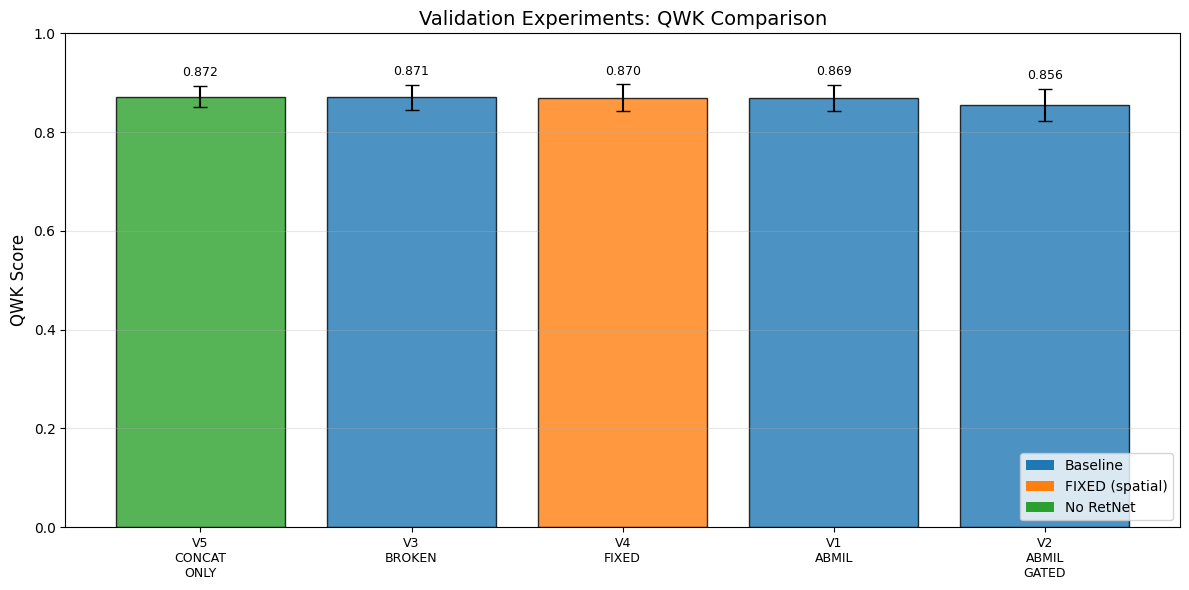

In [22]:
# 1. QWK Comparison Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))

exp_ids = [exp_id for exp_id, _ in sorted_results]
qwk_means = [r['qwk']['mean'] for _, r in sorted_results]
qwk_stds = [r['qwk']['std'] for _, r in sorted_results]

colors = ['#ff7f0e' if 'FIXED' in exp_id else
          '#2ca02c' if 'CONCAT_ONLY' in exp_id else
          '#1f77b4' for exp_id in exp_ids]

bars = ax.bar(range(len(exp_ids)), qwk_means, yerr=qwk_stds,
              capsize=5, color=colors, edgecolor='black', alpha=0.8)

ax.set_xticks(range(len(exp_ids)))
ax.set_xticklabels([e.replace('_', '\n') for e in exp_ids], rotation=0, fontsize=9)
ax.set_ylabel('QWK Score', fontsize=12)
ax.set_title('Validation Experiments: QWK Comparison', fontsize=14)
ax.set_ylim(0, 1.0)
ax.grid(axis='y', alpha=0.3)

# Add value labels
for i, (m, s) in enumerate(zip(qwk_means, qwk_stds)):
    ax.text(i, m + s + 0.02, f'{m:.3f}', ha='center', fontsize=9)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', label='Baseline'),
    Patch(facecolor='#ff7f0e', label='FIXED (spatial)'),
    Patch(facecolor='#2ca02c', label='No RetNet'),
]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'qwk_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipython-input-41926006.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(qwk_data, labels=[e.replace('_', '\n') for e in exp_ids], patch_artist=True)


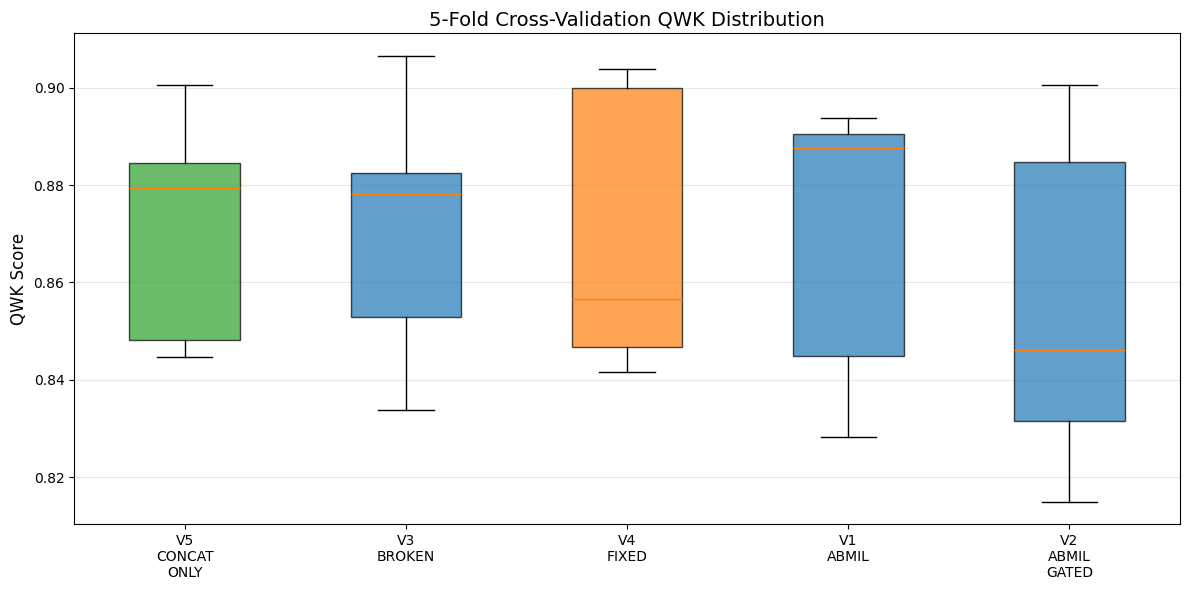

In [23]:
# 2. Box Plot of 5-fold QWK Distribution
fig, ax = plt.subplots(figsize=(12, 6))

qwk_data = [r['qwk']['values'] for _, r in sorted_results]

bp = ax.boxplot(qwk_data, labels=[e.replace('_', '\n') for e in exp_ids], patch_artist=True)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('QWK Score', fontsize=12)
ax.set_title('5-Fold Cross-Validation QWK Distribution', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'qwk_boxplot.png'), dpi=300, bbox_inches='tight')
plt.show()

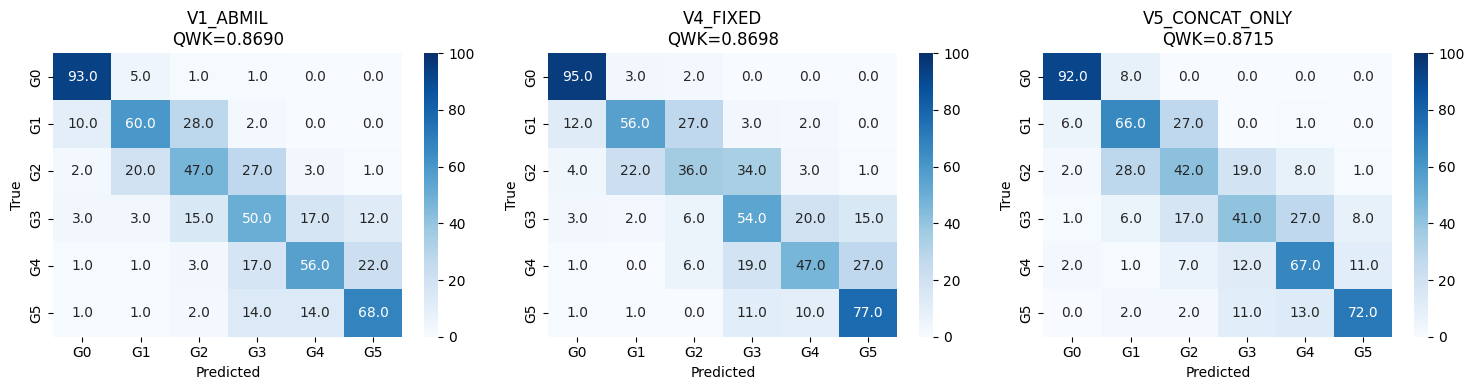

In [24]:
# 3. Confusion Matrices for Key Models
key_models = ['V1_ABMIL', 'V4_FIXED', 'V5_CONCAT_ONLY']
available_keys = [k for k in key_models if k in all_results]

fig, axes = plt.subplots(1, len(available_keys), figsize=(5*len(available_keys), 4))
if len(available_keys) == 1:
    axes = [axes]

for ax, exp_id in zip(axes, available_keys):
    cm = np.array(all_results[exp_id]['total_confusion_matrix'])
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues', ax=ax,
                xticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
                yticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
                vmin=0, vmax=100)
    ax.set_title(f'{exp_id}\nQWK={all_results[exp_id]["qwk"]["mean"]:.4f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'confusion_matrices.png'), dpi=300, bbox_inches='tight')
plt.show()

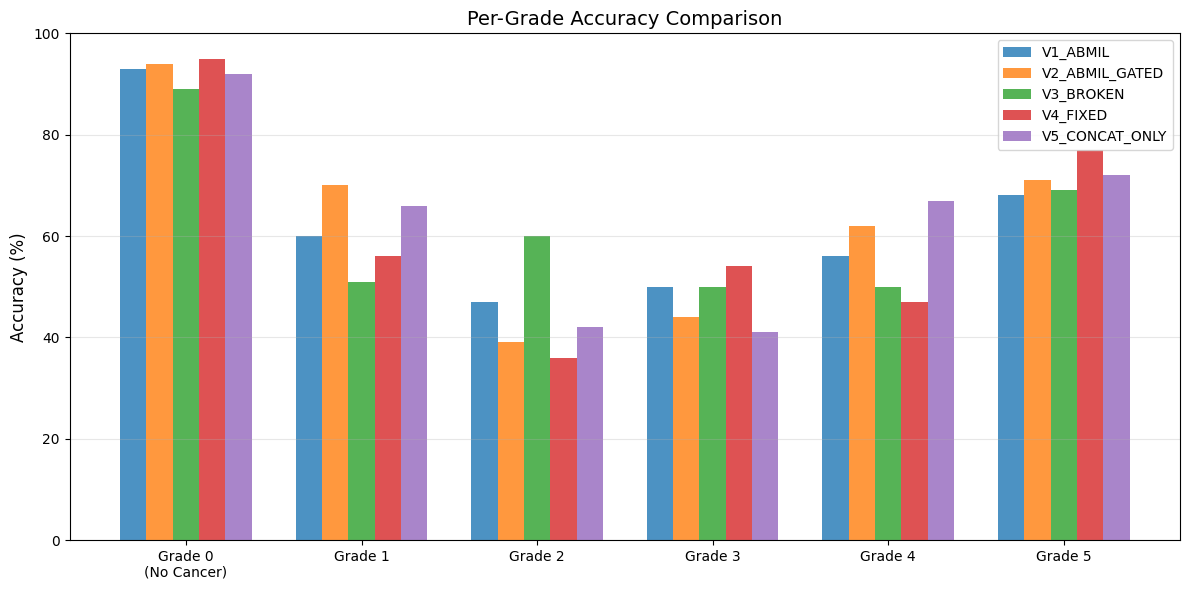

In [25]:
# 4. Per-Grade Accuracy Comparison
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(6)  # 6 grades
width = 0.15

key_models = ['V1_ABMIL', 'V2_ABMIL_GATED', 'V3_BROKEN', 'V4_FIXED', 'V5_CONCAT_ONLY']
available_keys = [k for k in key_models if k in all_results]

for i, exp_id in enumerate(available_keys):
    r = all_results[exp_id]
    accs = [r['per_grade_accuracy'].get(g, r['per_grade_accuracy'].get(str(g), {'mean': 0}))['mean'] * 100
            for g in range(6)]
    offset = (i - len(available_keys)/2 + 0.5) * width
    ax.bar(x + offset, accs, width, label=exp_id, alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(['Grade 0\n(No Cancer)', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'])
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Per-Grade Accuracy Comparison', fontsize=14)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'per_grade_accuracy.png'), dpi=300, bbox_inches='tight')
plt.show()

---

# PART 8: FINAL SUMMARY

In [26]:
print('\n' + '=' * 80)
print('FINAL SUMMARY')
print('=' * 80)

# Find best model
best_exp, best_result = sorted_results[0]

print(f'''
BEST MODEL: {best_exp}
  Description: {best_result['description']}
  QWK:         {best_result['qwk']['mean']:.4f} ± {best_result['qwk']['std']:.4f}
  Parameters:  {best_result['params']:,}

CONCLUSIONS:
''')

# Generate conclusions
conclusions = []

if arch_helps:
    conclusions.append(f"✓ Your architecture (CLAM+RetNet+ConcatFusion) improves over ABMIL by {(v3_qwk - v1_qwk):.4f} QWK")
else:
    conclusions.append(f"✗ Simple ABMIL achieves similar results ({v1_qwk:.4f} vs {v3_qwk:.4f})")

if fix_helps:
    conclusions.append(f"✓ FIXING the spatial decay (using coords) improves by {(v4_qwk - v3_qwk):.4f} QWK")
else:
    conclusions.append(f"✗ Spatial decay does not significantly improve results")

if retnet_needed:
    conclusions.append(f"✓ RetNet branch is needed (V4={v4_qwk:.4f} vs V5={v5_qwk:.4f})")
else:
    conclusions.append(f"✗ ConcatFusion alone achieves similar results (RetNet not needed)")
    conclusions.append(f"  → Your contribution may be ConcatFusion, not RetNet")

for c in conclusions:
    print(f"  {c}")

print(f'''
RECOMMENDATION:
''')

if fix_helps and retnet_needed:
    print("  → Use V4_FIXED as your final model")
    print("  → Spatial retention (RetNet) IS your contribution")
elif not retnet_needed and v5_qwk > v1_qwk + 0.01:
    print("  → ConcatFusion is the key contribution, not RetNet")
    print("  → Consider focusing thesis on dual-branch fusion")
else:
    print("  → Need to investigate further")
    print("  → Consider simpler architecture or different approach")

print('=' * 80)


FINAL SUMMARY

BEST MODEL: V5_CONCAT_ONLY
  Description: CLAM + ConcatFusion WITHOUT RetNet
  QWK:         0.8715 ± 0.0216
  Parameters:  1,580,295

CONCLUSIONS:

  ✗ Simple ABMIL achieves similar results (0.8690 vs 0.8708)
  ✗ Spatial decay does not significantly improve results
  ✗ ConcatFusion alone achieves similar results (RetNet not needed)
    → Your contribution may be ConcatFusion, not RetNet

RECOMMENDATION:

  → Need to investigate further
  → Consider simpler architecture or different approach


In [27]:
# Save final summary
summary = {
    'timestamp': datetime.now().isoformat(),
    'experiments_run': list(all_results.keys()),
    'best_model': best_exp,
    'best_qwk': best_result['qwk']['mean'],
    'best_qwk_std': best_result['qwk']['std'],

    'abmil_baseline_qwk': v1_qwk,
    'architecture_improvement': v3_qwk - v1_qwk,
    'fix_improvement': v4_qwk - v3_qwk,
    'retnet_contribution': v4_qwk - v5_qwk,

    'conclusions': {
        'architecture_helps': arch_helps,
        'spatial_fix_helps': fix_helps,
        'retnet_needed': retnet_needed,
    },

    'all_results': {k: {
        'qwk_mean': v['qwk']['mean'],
        'qwk_std': v['qwk']['std'],
        'qwk_values': v['qwk']['values'],
        'grading_accuracy': v['grading_accuracy']['mean'],
        'params': v['params'],
    } for k, v in all_results.items()}
}

with open(os.path.join(CONFIG['results_dir'], 'v16_final_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print(f"\nResults saved to: {CONFIG['results_dir']}")
print('\nDONE!')

TypeError: Object of type bool is not JSON serializable